# Phase 1.5 Session 2: Fine-tune Cellpose on BBBC038

Goal: Fine-tune the pretrained Cellpose 'nuclei' model on BBBC038 stage1_train
(images with ground-truth masks), then compare segmentation before vs. after
fine-tuning on held-out test images (stage1_test).

Method: Colab + T4 GPU, cellpose<4. train.train_seg on a 200-image subset
(train 180 / val 20), n_epochs=100. Evaluation with CellposeModel on 6 test images:
nucleus count, mean area, visual side-by-side.






In [3]:
%pip install -q "cellpose<4"


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dm-tree 0.1.10 requires numpy>=2.1.0; python_version >= "3.13", but you have numpy 2.0.2 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.1.0; python_version >= "3.13", but you have numpy 2.0.2 which is incompatible.
jax 0.11.1 requires numpy>=2.1, but you have numpy 2.0.2 which is incompatible.


In [4]:
!nvidia-smi


Mon Oct 26 22:44:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
!wget -q https://data.broadinstitute.org/bbbc/BBBC038/stage1_train.zip -O /content/stage1_train.zip
!unzip -q -o /content/stage1_train.zip -d /content/bbbc038_train
!wget -q https://data.broadinstitute.org/bbbc/BBBC038/stage1_test.zip -O /content/stage1_test.zip
!unzip -q -o /content/stage1_test.zip -d /content/bbbc038_test

import glob
import numpy as np
from skimage import io

def load_gray(path):
    im = io.imread(path)
    if im.ndim == 3:              # RGB/RGBA → グレースケール化（セッション1と同じ）
        im = im[..., :3].mean(axis=-1)
    return im

def merge_masks(mask_files):
    """核ごとのマスクPNGを1枚のラベル画像に統合（0=背景, 1..N=核）"""
    lab = np.zeros(io.imread(mask_files[0]).shape, dtype=np.int32)
    for i, mf in enumerate(sorted(mask_files), start=1):
        lab[io.imread(mf) > 0] = i
    return lab

train_imgs, train_masks = [], []
for folder in sorted(glob.glob('/content/bbbc038_train/*/')):
    img_path = sorted(glob.glob(folder + 'images/*.png'))[0]
    mask_files = glob.glob(folder + 'masks/*.png')
    if not mask_files:
        continue
    train_imgs.append(load_gray(img_path))
    train_masks.append(merge_masks(mask_files))

print('train images:', len(train_imgs))          # 670 と出ればOK
print('sample image:', train_imgs[0].shape, train_imgs[0].dtype)
print('sample labels: max =', train_masks[0].max(), '(= この画像の核数)')

test_files = sorted(glob.glob('/content/bbbc038_test/*/images/*.png'))
print('test images:', len(test_files))          # 65 と出ればOK


train images: 670
sample image: (256, 256) float64
sample labels: max = 27 (= この画像の核数)
test images: 65


train: 180 val: 20


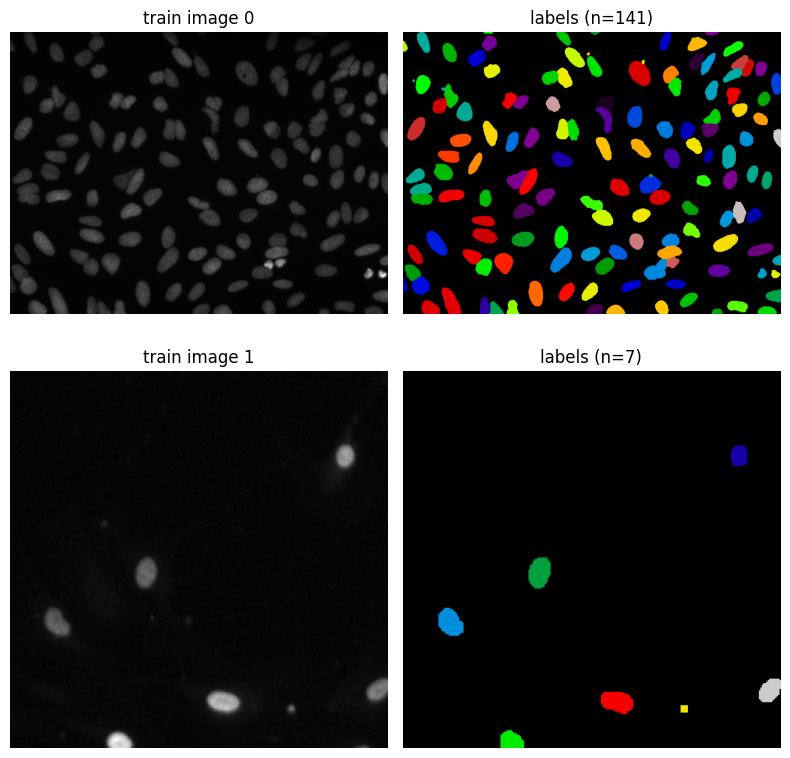

100%|██████████| 25.3M/25.3M [00:00<00:00, 28.3MB/s]
/usr/local/lib/python3.13/dist-packages/cellpose/dynamics.py:760: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


      image  n_base  mean_area_base
0  0114f484       4      145.000000
1  0999dab0      59      431.559322
2  0a849e0e      42      261.476190
3  0e132f71       2      145.000000
4  0ed3555a      12       62.666667
5  0f1f896d      21      756.904762
total nuclei (6 imgs): 140


In [6]:
import matplotlib.pyplot as plt

rng = np.random.RandomState(0)
perm = rng.permutation(len(train_imgs))
N_SUBSET = 200
sub = perm[:N_SUBSET]
tr_idx, va_idx = sub[:180], sub[180:]
tr_imgs = [train_imgs[i] for i in tr_idx]
tr_masks = [train_masks[i] for i in tr_idx]
va_imgs = [train_imgs[i] for i in va_idx]
va_masks = [train_masks[i] for i in va_idx]
print('train:', len(tr_imgs), 'val:', len(va_imgs))

# ラベルの目視QC（正解マスクが画像と合っているか2枚だけ確認）
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
for j in range(2):
    axes[j, 0].imshow(tr_imgs[j], cmap='gray'); axes[j, 0].set_title('train image %d' % j); axes[j, 0].axis('off')
    axes[j, 1].imshow(tr_masks[j], cmap='nipy_spectral'); axes[j, 1].set_title('labels (n=%d)' % int(tr_masks[j].max())); axes[j, 1].axis('off')
plt.tight_layout(); plt.show()

# 学習前のベースライン：セッション1と同じ6枚のテスト画像を素の nuclei モデルで回す
from cellpose import models
base_model = models.CellposeModel(gpu=True, model_type='nuclei')

base_rows = []
for f in test_files[:6]:
    g = load_gray(f)
    m, _, _ = base_model.eval(g, channels=[0, 0])
    base_rows.append({'image': f.split('/')[-3][:8], 'n_base': int(m.max()),
                      'mean_area_base': float((m > 0).sum() / max(m.max(), 1))})
import pandas as pd
base_df = pd.DataFrame(base_rows)
print(base_df)
print('total nuclei (6 imgs):', base_df['n_base'].sum())


100%|██████████| 20/20 [00:00<00:00, 1554.31it/s]


elapsed: 15.0 min
model saved to: /content/models/finetuned_nuclei


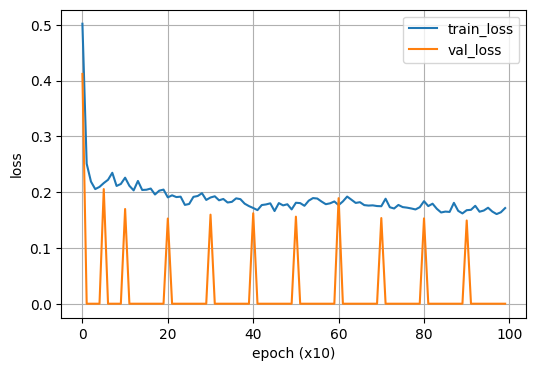

In [7]:
from cellpose import train
import time

t0 = time.time()
model_path, train_losses, test_losses = train.train_seg(
    base_model.net,
    train_data=tr_imgs, train_labels=tr_masks,
    test_data=va_imgs, test_labels=va_masks,   # val 20枚で test_loss を記録
    channels=[0, 0],
    n_epochs=100,
    save_path='/content',
    model_name='finetuned_nuclei',
)
print('elapsed: %.1f min' % ((time.time() - t0) / 60))
print('model saved to:', model_path)

# 損失曲線（train_loss が下がり、test_loss がそれを追っていれば学習は健全）
plt.figure(figsize=(6, 4))
plt.plot(train_losses, label='train_loss')
plt.plot(test_losses, label='val_loss')
plt.xlabel('epoch (x10)'); plt.ylabel('loss'); plt.legend(); plt.grid(True)
plt.savefig('/content/finetune_losses.png', dpi=150)
plt.show()


   image  n_base  n_finetuned  mean_area_base  mean_area_ft
0114f484       7            7      153.285714    191.857143
0999dab0      57           57      454.192982    483.947368
0a849e0e      42           39      302.880952    351.641026
0e132f71       8            9      132.250000    190.333333
0ed3555a      14           11       99.928571    152.636364
0f1f896d      24           33      473.875000    621.030303
total: base 152 -> finetuned 156


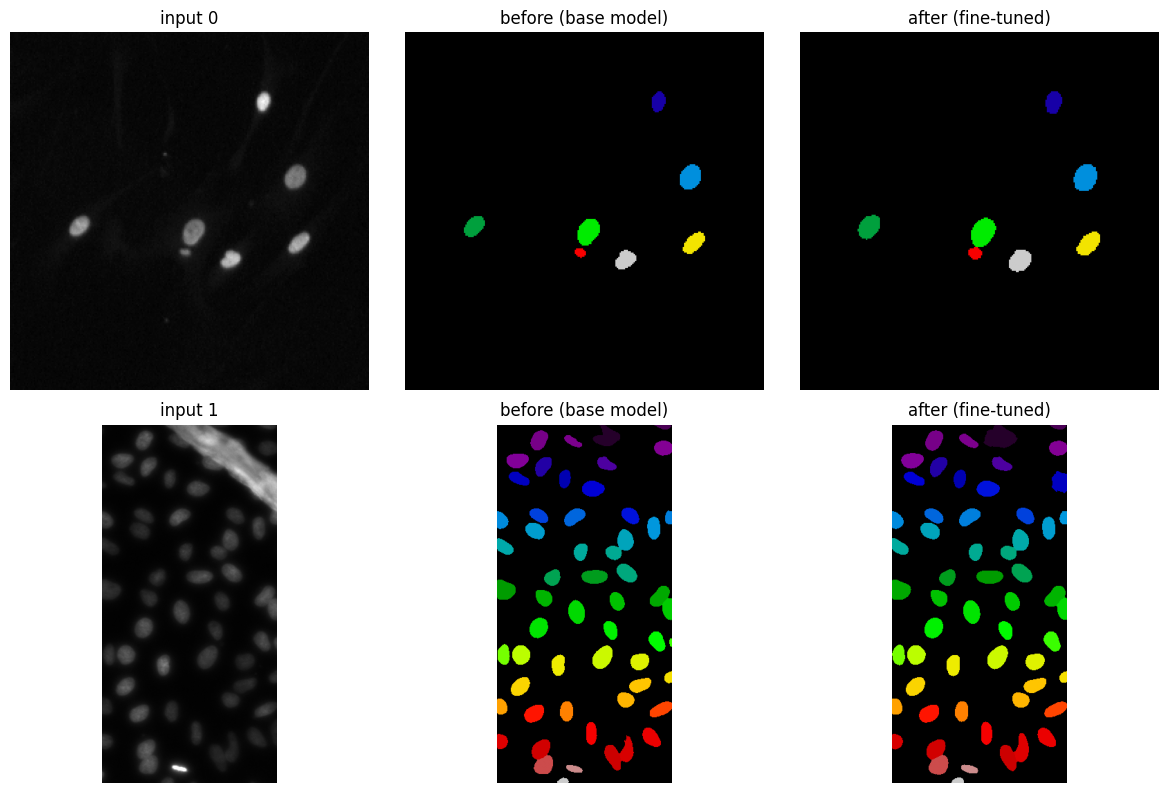

In [8]:
ft_model = models.CellposeModel(gpu=True, pretrained_model='/content/models/finetuned_nuclei')

cmp_rows, before_masks, after_masks = [], {}, {}
for k, f in enumerate(test_files[:6]):
    g = load_gray(f)
    mb, _, _ = base_model.eval(g, channels=[0, 0])
    ma, _, _ = ft_model.eval(g, channels=[0, 0])
    cmp_rows.append({'image': f.split('/')[-3][:8],
                     'n_base': int(mb.max()), 'n_finetuned': int(ma.max()),
                     'mean_area_base': float((mb > 0).sum() / max(mb.max(), 1)),
                     'mean_area_ft': float((ma > 0).sum() / max(ma.max(), 1))})
    if k < 2:
        before_masks[k] = mb; after_masks[k] = ma

cmp_df = pd.DataFrame(cmp_rows)
print(cmp_df.to_string(index=False))
print('total: base %d -> finetuned %d' % (cmp_df['n_base'].sum(), cmp_df['n_finetuned'].sum()))

# 目視比較（2枚分：入力｜学習前｜学習後）
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for k in range(2):
    g = load_gray(test_files[k])
    axes[k, 0].imshow(g, cmap='gray'); axes[k, 0].set_title('input %d' % k); axes[k, 0].axis('off')
    axes[k, 1].imshow(before_masks[k], cmap='nipy_spectral'); axes[k, 1].set_title('before (base model)'); axes[k, 1].axis('off')
    axes[k, 2].imshow(after_masks[k], cmap='nipy_spectral'); axes[k, 2].set_title('after (fine-tuned)'); axes[k, 2].axis('off')
plt.tight_layout()
plt.savefig('/content/finetune_before_after.png', dpi=150)
plt.show()


In [9]:
cmp_df.to_csv('/content/finetune_comparison.csv', index=False)
from google.colab import files
files.download('/content/finetune_comparison.csv')
files.download('/content/finetune_losses.png')
files.download('/content/finetune_before_after.png')
files.download('/content/models/finetuned_nuclei')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>